In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(r"F:\NTI Machine\NTI projects\Final Project\Telco_customer_churn.xlsx")

### Dataset Data Dictionary (IBM Telco Customer Churn — 33-Column Extended Version)

| Column Name | Data Type | Values / Range | Business & Modeling Description |
| :--- | :--- | :--- | :--- |
| **`CustomerID`** | Object (String) | Unique IDs (e.g., `3668-QPYBK`) | Unique customer identifier. **Drop** before modeling. |
| **`Count`** | Integer (Constant) | `1` | Constant row counter (`1` for all rows). **Drop** (zero variance). |
| **`Country`** | Object (Constant) | `United States` | Constant country value. **Drop** (zero variance). |
| **`State`** | Object (Constant) | `California` | Constant state value. **Drop** (zero variance). |
| **`City`** | Object (Categorical) | ~1,129 California cities | Customer city. High cardinality—use frequency encoding, top-N grouping, or rely on `Latitude`/`Longitude`. |
| **`Zip Code`** | Integer (Categorical) | `90001` to `96161` | Customer postal code. High cardinality—better represented via `Latitude`/`Longitude` or regional binning. |
| **`Lat Long`** | Object (String) | `"33.964131, -118.272783"` | Combined coordinate string. **Drop** (redundant with `Latitude` and `Longitude`). |
| **`Latitude`** | Float (Numeric) | `32.55` to `41.96` | Geographic latitude of customer residence. Useful for spatial clustering or regional churn patterns. |
| **`Longitude`** | Float (Numeric) | `-124.30` to `-114.19` | Geographic longitude of customer residence. |
| **`Gender`** | Object (Categorical) | `Male`, `Female` | Customer gender. Near-zero correlation with churn. |
| **`Senior Citizen`** | Object (Categorical) | `Yes`, `No` | Whether the customer is 65 or older. Senior citizens show noticeably higher churn rates. |
| **`Partner`** | Object (Categorical) | `Yes`, `No` | Whether the customer has a spouse/partner. Customers with partners churn less. |
| **`Dependents`** | Object (Categorical) | `Yes`, `No` | Whether the customer lives with dependents. Strongly associated with lower churn. |
| **`Tenure Months`** | Integer (Numeric) | `0` to `72` (months) | Months the customer has stayed with the company. Strongest numerical predictor—churn spikes in months 1–12. |
| **`Phone Service`** | Object (Categorical) | `Yes`, `No` | Whether the customer subscribes to home phone service. |
| **`Multiple Lines`** | Object (Categorical) | `Yes`, `No`, `No phone service` | Multiple phone lines (`No phone service` overlaps with `Phone Service == No`). |
| **`Internet Service`** | Object (Categorical) | `DSL`, `Fiber optic`, `No` | Internet connection type. `Fiber optic` users exhibit significantly higher churn. |
| **`Online Security`** | Object (Categorical) | `Yes`, `No`, `No internet service` | Add-on security package. Customers without online security churn much more. |
| **`Online Backup`** | Object (Categorical) | `Yes`, `No`, `No internet service` | Add-on cloud backup service. Acts as a retention anchor. |
| **`Device Protection`** | Object (Categorical) | `Yes`, `No`, `No internet service` | Add-on device protection plan. Reduces churn likelihood. |
| **`Tech Support`** | Object (Categorical) | `Yes`, `No`, `No internet service` | Add-on technical support. Lack of tech support strongly correlates with churn. |
| **`Streaming TV`** | Object (Categorical) | `Yes`, `No`, `No internet service` | Add-on TV streaming service. Increases monthly bill; moderate link to churn. |
| **`Streaming Movies`** | Object (Categorical) | `Yes`, `No`, `No internet service` | Add-on movie streaming service. Similar behavior to `Streaming TV`. |
| **`Contract`** | Object (Categorical) | `Month-to-month`, `One year`, `Two year` | Billing contract term. Strongest categorical predictor—`Month-to-month` drives most churn. |
| **`Paperless Billing`** | Object (Categorical) | `Yes`, `No` | Digital billing flag. Paperless billing users show higher churn rates. |
| **`Payment Method`** | Object (Categorical) | `Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)` | Payment channel. `Electronic check` users churn far more frequently than auto-pay users. |
| **`Monthly Charges`** | Float (Numeric) | `~$18.25` to `$118.75` | Current monthly charge. Higher bills correlate with higher churn (especially on Fiber optic). |
| **`Total Charges`** | Object → Float (Numeric) | `~$18.80` to `$8,684.80` (plus `" "` blanks) | Cumulative amount charged. Stored as string due to 11 blank spaces where `Tenure Months == 0`. |
| **`Churn Label`** | Object (Target Duplicate) | `Yes`, `No` | String version of the target. **Drop** before modeling (use `Churn Value` as `y`). |
| **`Churn Value`** *(Target)* | Integer (Binary) | `0` (~73.5%), `1` (~26.5%) | Binary target variable (`1` = Churned, `0` = Retained). |
| **`Churn Score`** | Integer (Leakage) | `5` to `100` | Pre-computed IBM churn risk score. **MUST DROP**—causes severe data leakage. |
| **`CLTV`** | Integer (Numeric) | `2,003` to `6,500` | Customer Lifetime Value predicted by IBM. Keep as a feature or test with/without to verify no leakage. |
| **`Churn Reason`** | Object (Leakage) | 20 text reasons + `NaN` | Exit survey reason recorded *after* churn (`NaN` for non-churners). **Use in EDA only; MUST DROP before modeling.** |

In [3]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [5]:
df.shape

(7043, 33)

In [6]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [7]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [8]:
df.drop(columns = ['Churn Reason'],inplace = True)

In [9]:
df.isnull().sum().sort_values(ascending=False
)

CustomerID           0
Count                0
Churn Score          0
Churn Value          0
Churn Label          0
Total Charges        0
Monthly Charges      0
Payment Method       0
Paperless Billing    0
Contract             0
Streaming Movies     0
Streaming TV         0
Tech Support         0
Device Protection    0
Online Backup        0
Online Security      0
Internet Service     0
Multiple Lines       0
Phone Service        0
Tenure Months        0
Dependents           0
Partner              0
Senior Citizen       0
Gender               0
Longitude            0
Latitude             0
Lat Long             0
Zip Code             0
City                 0
State                0
Country              0
CLTV                 0
dtype: int64

In [10]:
for col in df.select_dtypes("O"):
    print(f"{col} uniques:",df[col].unique())
    print(f"{col} number of uniques:",df[col].nunique())
    print("__________________________________________________")

CustomerID uniques: ['3668-QPYBK' '9237-HQITU' '9305-CDSKC' ... '2234-XADUH' '4801-JZAZL'
 '3186-AJIEK']
CustomerID number of uniques: 7043
__________________________________________________
Country uniques: ['United States']
Country number of uniques: 1
__________________________________________________
State uniques: ['California']
State number of uniques: 1
__________________________________________________
City uniques: ['Los Angeles' 'Beverly Hills' 'Huntington Park' ... 'Standish' 'Tulelake'
 'Olympic Valley']
City number of uniques: 1129
__________________________________________________
Lat Long uniques: ['33.964131, -118.272783' '34.059281, -118.30742' '34.048013, -118.293953'
 ... '40.346634, -120.386422' '41.813521, -121.492666'
 '39.191797, -120.212401']
Lat Long number of uniques: 1652
__________________________________________________
Gender uniques: ['Male' 'Female']
Gender number of uniques: 2
__________________________________________________
Senior Citizen uniques: ['

In [11]:
val_to_drop = ['CustomerID','Country','State','Lat Long']

In [12]:
df.drop(columns = val_to_drop, inplace = True)

In [13]:
for col in df.select_dtypes("O"):
    print(f"{col} uniques:",df[col].unique())
    print(f"{col} number of uniques:",df[col].nunique())
    print("__________________________________________________")

City uniques: ['Los Angeles' 'Beverly Hills' 'Huntington Park' ... 'Standish' 'Tulelake'
 'Olympic Valley']
City number of uniques: 1129
__________________________________________________
Gender uniques: ['Male' 'Female']
Gender number of uniques: 2
__________________________________________________
Senior Citizen uniques: ['No' 'Yes']
Senior Citizen number of uniques: 2
__________________________________________________
Partner uniques: ['No' 'Yes']
Partner number of uniques: 2
__________________________________________________
Dependents uniques: ['No' 'Yes']
Dependents number of uniques: 2
__________________________________________________
Phone Service uniques: ['Yes' 'No']
Phone Service number of uniques: 2
__________________________________________________
Multiple Lines uniques: ['No' 'Yes' 'No phone service']
Multiple Lines number of uniques: 3
__________________________________________________
Internet Service uniques: ['DSL' 'Fiber optic' 'No']
Internet Service number of uniq

In [14]:
df.head()

,Count,City,Zip Code,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,...,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV
0,1,Los Angeles,90003,33.964131,-118.272783,Male,No,No,No,2,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239
1,1,Los Angeles,90005,34.059281,-118.307420,Female,No,No,Yes,2,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701
2,1,Los Angeles,90006,34.048013,-118.293953,Female,No,No,Yes,8,...,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372
3,1,Los Angeles,90010,34.062125,-118.315709,Female,No,Yes,Yes,28,...,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003
4,1,Los Angeles,90015,34.039224,-118.266293,Male,No,No,Yes,49,...,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340


In [15]:
df.drop(columns= ['Count','Zip Code','Latitude','Longitude','Churn Label','Churn Score'], inplace = True)

In [16]:
df.head()

,City,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,CLTV
0,Los Angeles,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,3239
1,Los Angeles,Female,No,No,Yes,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,2701
2,Los Angeles,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,1,5372
3,Los Angeles,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1,5003
4,Los Angeles,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,1,5340


In [17]:
df.describe(include="O")

,City,Gender,Senior Citizen,Partner,Dependents,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Total Charges
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.0
unique,1129,2,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531.0
top,Los Angeles,Male,No,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2
freq,305,3555,5901,3641,5416,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11.0


In [18]:
df.select_dtypes(include="number")

,Tenure Months,Monthly Charges,Churn Value,CLTV
0,2,53.85,1,3239
1,2,70.70,1,2701
2,8,99.65,1,5372
3,28,104.80,1,5003
4,49,103.70,1,5340
...,...,...,...,...
7038,72,21.15,0,5306
7039,24,84.80,0,2140
7040,72,103.20,0,5560
7041,11,29.60,0,2793


In [19]:
df['Total Charges'] = pd.to_numeric(
    df['Total Charges'],
    errors='coerce'
)

In [20]:
df.select_dtypes(include="number")

,Tenure Months,Monthly Charges,Total Charges,Churn Value,CLTV
0,2,53.85,108.15,1,3239
1,2,70.70,151.65,1,2701
2,8,99.65,820.50,1,5372
3,28,104.80,3046.05,1,5003
4,49,103.70,5036.30,1,5340
...,...,...,...,...,...
7038,72,21.15,1419.40,0,5306
7039,24,84.80,1990.50,0,2140
7040,72,103.20,7362.90,0,5560
7041,11,29.60,346.45,0,2793


In [21]:
df.isnull().sum()

City                  0
Gender                0
Senior Citizen        0
Partner               0
Dependents            0
Tenure Months         0
Phone Service         0
Multiple Lines        0
Internet Service      0
Online Security       0
Online Backup         0
Device Protection     0
Tech Support          0
Streaming TV          0
Streaming Movies      0
Contract              0
Paperless Billing     0
Payment Method        0
Monthly Charges       0
Total Charges        11
Churn Value           0
CLTV                  0
dtype: int64

In [22]:
df.dropna(inplace=True)

In [23]:
for col in df.select_dtypes("O"):
    print(f"{col} uniques:",df[col].unique())
    print(f"{col} number of uniques:",df[col].nunique())
    print("__________________________________________________")

City uniques: ['Los Angeles' 'Beverly Hills' 'Huntington Park' ... 'Tulelake'
 'Olympic Valley' 'Redcrest']
City number of uniques: 1129
__________________________________________________
Gender uniques: ['Male' 'Female']
Gender number of uniques: 2
__________________________________________________
Senior Citizen uniques: ['No' 'Yes']
Senior Citizen number of uniques: 2
__________________________________________________
Partner uniques: ['No' 'Yes']
Partner number of uniques: 2
__________________________________________________
Dependents uniques: ['No' 'Yes']
Dependents number of uniques: 2
__________________________________________________
Phone Service uniques: ['Yes' 'No']
Phone Service number of uniques: 2
__________________________________________________
Multiple Lines uniques: ['No' 'Yes' 'No phone service']
Multiple Lines number of uniques: 3
__________________________________________________
Internet Service uniques: ['DSL' 'Fiber optic' 'No']
Internet Service number of uniq

In [24]:
df.duplicated().sum()


0

In [25]:
df.isnull().sum().sum()

0

C:\Users\yawaa\AppData\Local\Temp\ipykernel_31576\1473784852.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Retained", "Churned"])


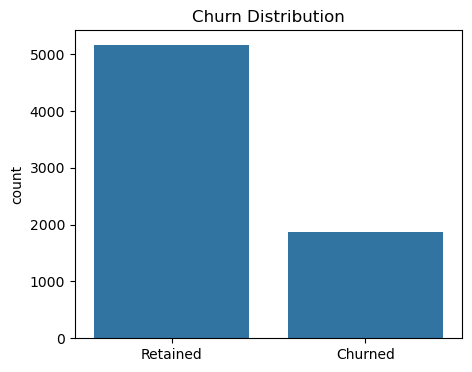

Churn Value
0    0.734215
1    0.265785
Name: proportion, dtype: float64

In [42]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn Value", ax=ax)
ax.set_xticklabels(["Retained", "Churned"])
ax.set_xlabel("")
ax.set_title("Churn Distribution")
plt.show()
df["Churn Value"].value_counts(normalize=True)

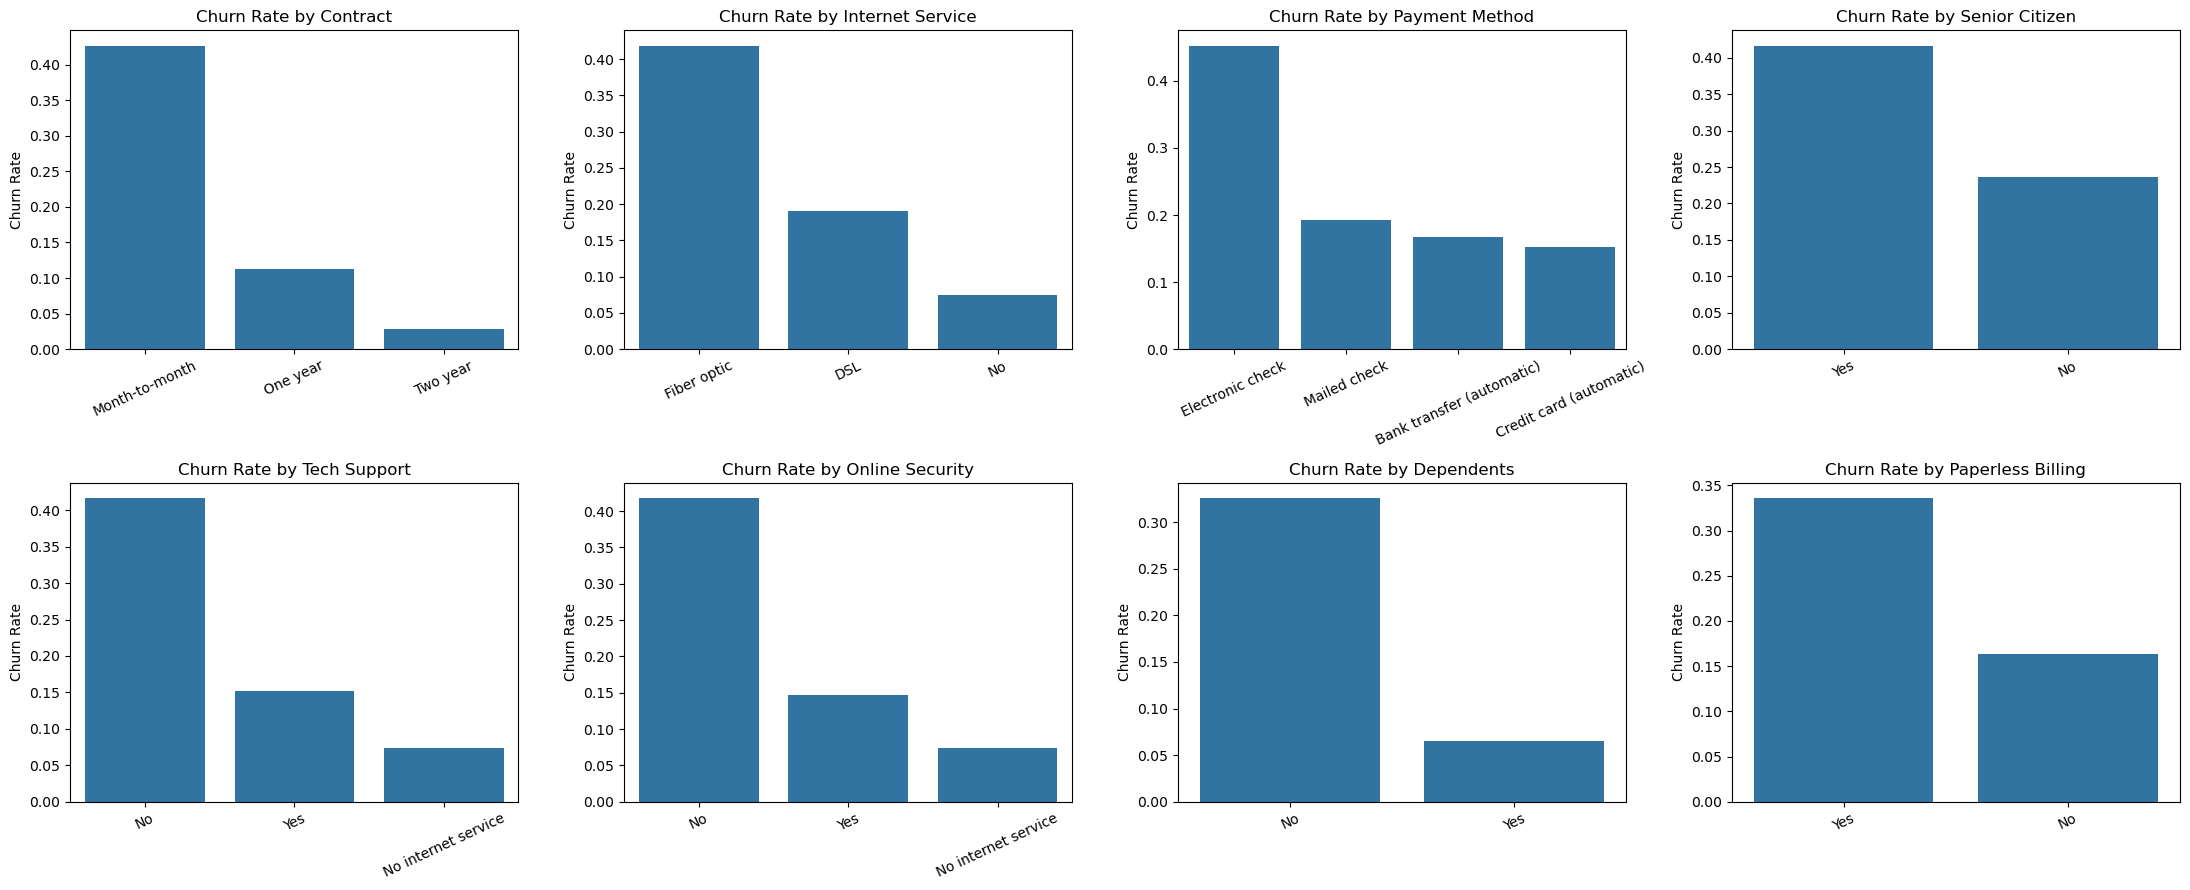

In [43]:
eda_cols = ["Contract", "Internet Service", "Payment Method", "Senior Citizen",
            "Tech Support", "Online Security", "Dependents", "Paperless Billing"]

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, col in zip(axes.ravel(), eda_cols):
    rate = df.groupby(col)["Churn Value"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn Rate")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

C:\Users\yawaa\AppData\Local\Temp\ipykernel_31576\423703241.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Retained", "Churned"])
C:\Users\yawaa\AppData\Local\Temp\ipykernel_31576\423703241.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(["Retained", "Churned"])


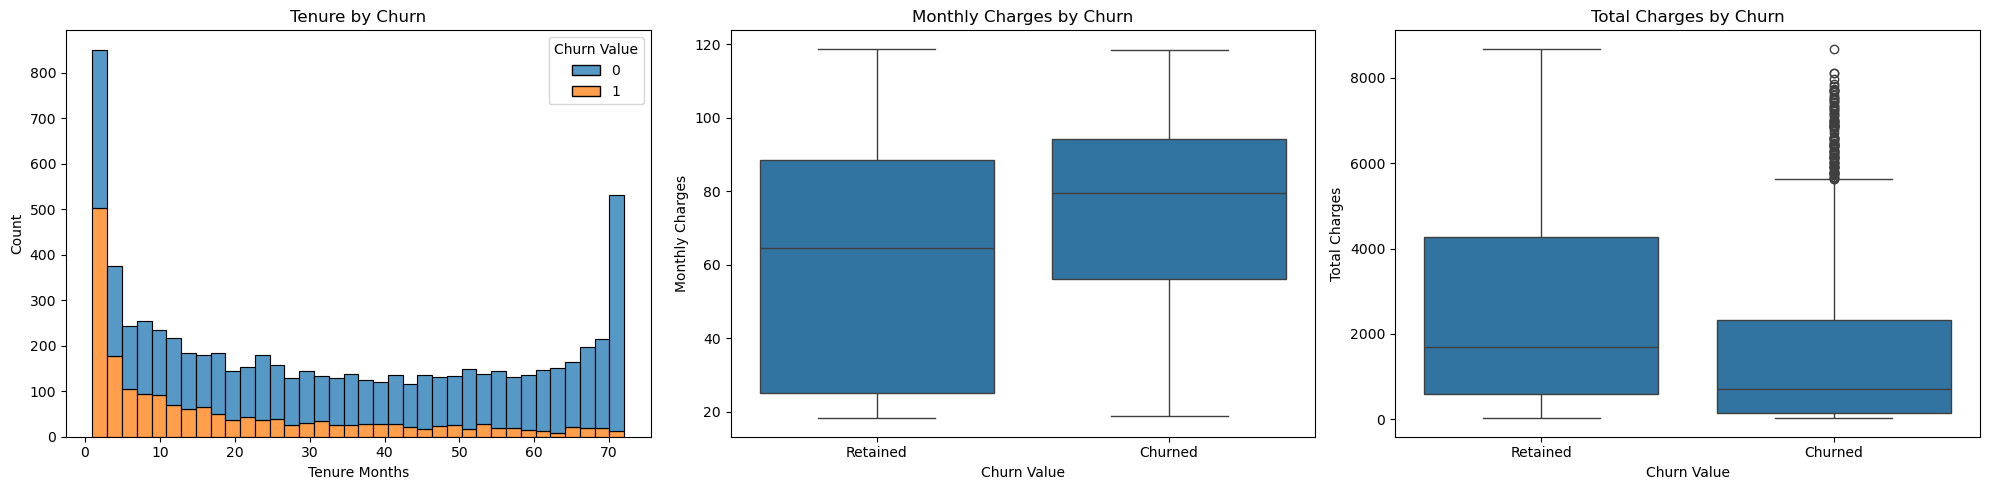

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.histplot(data=df, x="Tenure Months", hue="Churn Value", bins=36, multiple="stack", ax=axes[0])
axes[0].set_title("Tenure by Churn")

sns.boxplot(data=df, x="Churn Value", y="Monthly Charges", ax=axes[1])
axes[1].set_xticklabels(["Retained", "Churned"])
axes[1].set_title("Monthly Charges by Churn")

sns.boxplot(data=df, x="Churn Value", y="Total Charges", ax=axes[2])
axes[2].set_xticklabels(["Retained", "Churned"])
axes[2].set_title("Total Charges by Churn")

plt.tight_layout()
plt.show()

In [26]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=["Churn Value", "City"], errors="ignore")
y = df["Churn Value"]

X_train_scaled, X_test_scaled, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train_scaled.shape, "| X_test:", X_test_scaled.shape)

X_train: (5625, 20) | X_test: (1407, 20)


In [27]:
from sklearn.preprocessing import LabelEncoder


cat_cols = X_train_scaled.select_dtypes(include=["object", "category"]).columns.tolist()


encoders = {}

X_train_encoded = X_train_scaled.copy()
X_test_encoded = X_test_scaled.copy()

for col in cat_cols:
    le = LabelEncoder()
    X_train_encoded[col] = le.fit_transform(X_train_scaled[col])
    X_test_encoded[col] = le.transform(X_test_scaled[col])
    encoders[col] = le

print("Encoded columns:", cat_cols)
X_train_encoded.head()

Encoded columns: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,CLTV
2907,1,0,1,1,65,1,2,1,2,2,2,2,0,0,2,0,1,94.55,6078.75,4603
7014,1,0,0,0,26,0,1,0,0,0,2,2,0,0,0,0,2,35.75,1022.50,2734
4346,0,0,1,0,68,1,2,1,0,2,2,2,0,0,2,0,1,90.20,6297.65,4095
5186,1,0,0,0,3,1,0,1,0,2,0,0,0,2,0,0,2,84.30,235.05,5828
4485,0,0,1,0,49,0,1,0,2,0,0,0,2,0,0,0,0,40.65,2070.75,5565


In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_encoded),
    columns=X_train_encoded.columns,
    index=X_train_encoded.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_encoded),
    columns=X_test_encoded.columns,
    index=X_test_encoded.index
)

X_train_scaled.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,CLTV
2907,0.996274,-0.439319,1.028312,1.822163,1.321816,0.327542,1.112139,0.175326,1.407662,1.229379,1.241630,1.383546,-1.120302,-1.123089,1.567119,-1.21303,-0.535318,0.981556,1.659900,0.164463
7014,0.996274,-0.439319,-0.972468,-0.548798,-0.267410,-3.053048,0.058090,-1.183089,-0.916406,-1.037918,1.241630,1.383546,-1.120302,-1.123089,-0.830880,-1.21303,0.403324,-0.971546,-0.562252,-1.415108
4346,-1.003740,-0.439319,1.028312,-0.548798,1.444064,0.327542,1.112139,0.175326,-0.916406,1.229379,1.241630,1.383546,-1.120302,-1.123089,1.567119,-1.21303,-0.535318,0.837066,1.756104,-0.264870
5186,0.996274,-0.439319,-0.972468,-0.548798,-1.204646,0.327542,-0.995959,0.175326,-0.916406,1.229379,-1.028168,-0.930592,-1.120302,1.133923,-0.830880,-1.21303,0.403324,0.641092,-0.908326,1.199762
4485,-1.003740,-0.439319,1.028312,-0.548798,0.669826,-3.053048,0.058090,-1.183089,1.407662,-1.037918,-1.028168,-0.930592,1.136753,-1.123089,-0.830880,-1.21303,-1.473959,-0.808787,-0.101561,0.977489


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from tqdm import tqdm

In [30]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[908 125]
 [145 229]]


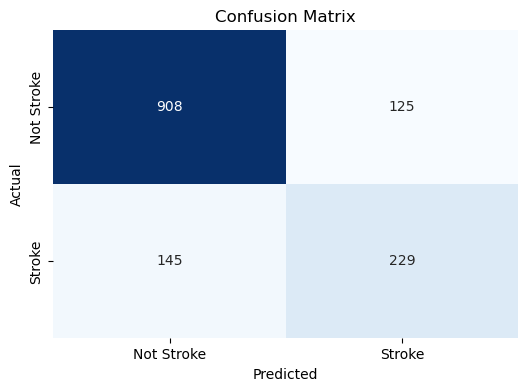


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.86      0.88      0.87      1033
      Stroke       0.65      0.61      0.63       374

    accuracy                           0.81      1407
   macro avg       0.75      0.75      0.75      1407
weighted avg       0.81      0.81      0.81      1407

ROC-AUC: 0.8422252822628655


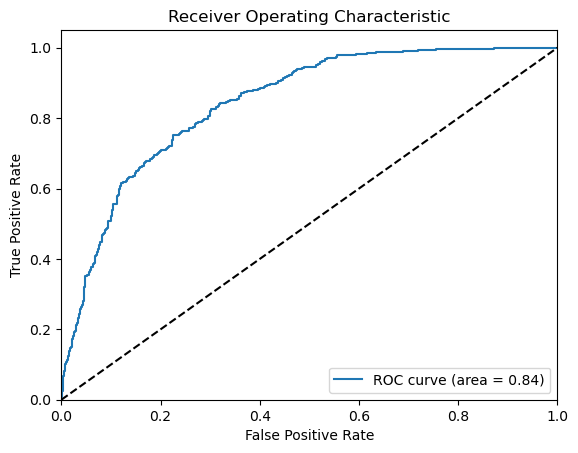

PR AUC: 0.6327276852871179


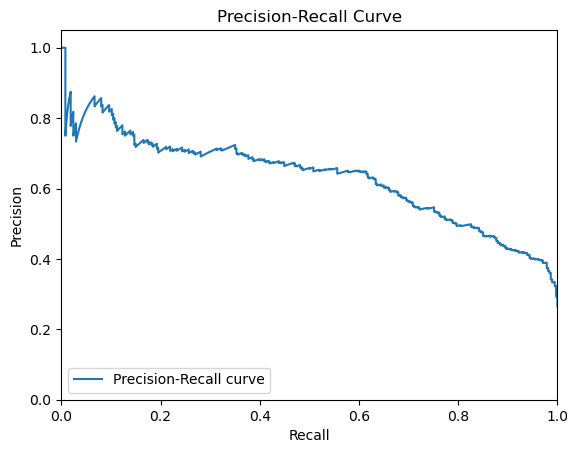

  8%|▊         | 1/13 [00:00<00:07,  1.64it/s]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar


Confusion Matrix:
 [[861 172]
 [162 212]]


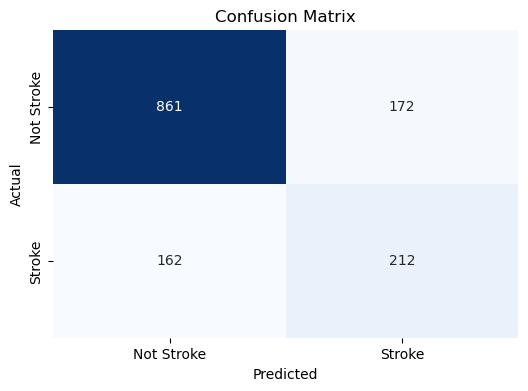


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.83      0.84      1033
      Stroke       0.55      0.57      0.56       374

    accuracy                           0.76      1407
   macro avg       0.70      0.70      0.70      1407
weighted avg       0.76      0.76      0.76      1407

ROC-AUC: 0.7841756785438808


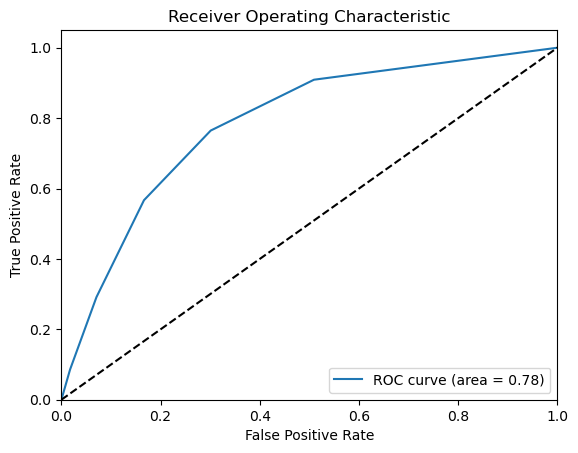

PR AUC: 0.5057463818175569


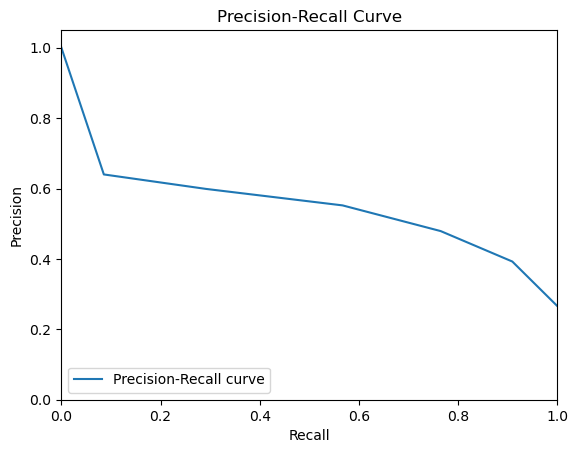

 15%|█▌        | 2/13 [00:01<00:11,  1.06s/it]e:\anaconda\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[916 117]
 [182 192]]


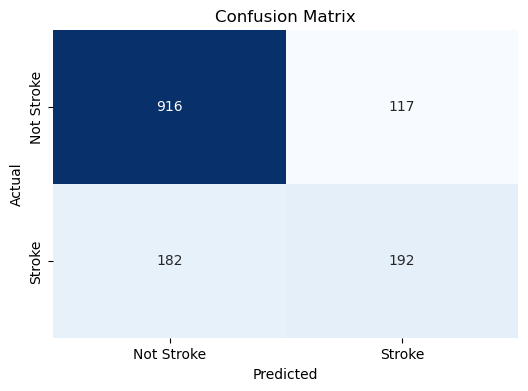


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.83      0.89      0.86      1033
      Stroke       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

ROC-AUC: 0.8048477773578849


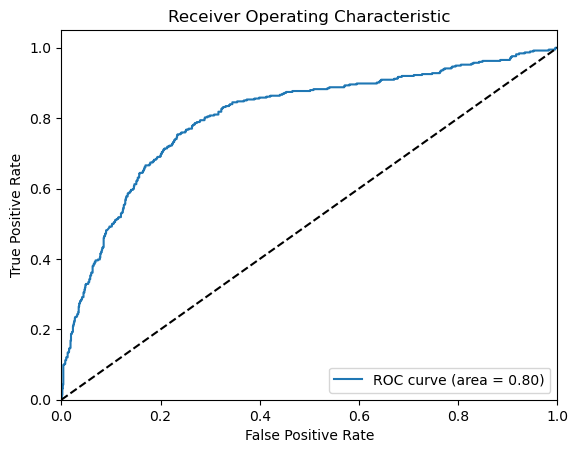

PR AUC: 0.6187376128022549


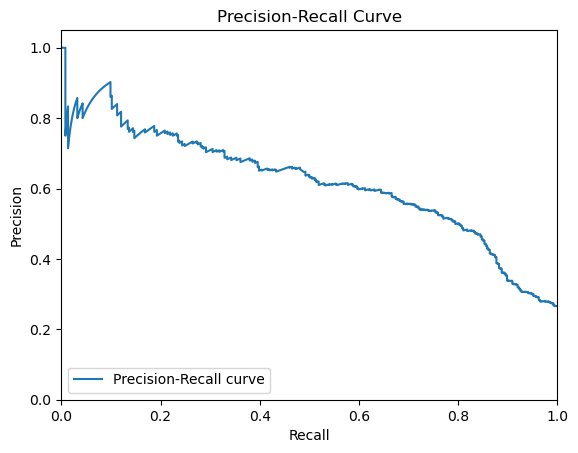

 23%|██▎       | 3/13 [00:10<00:46,  4.64s/it]


Confusion Matrix:
 [[835 198]
 [194 180]]


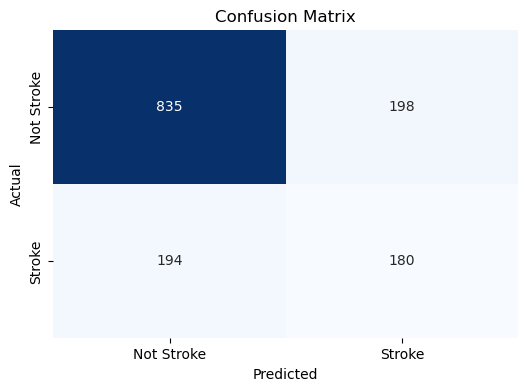


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.81      0.81      0.81      1033
      Stroke       0.48      0.48      0.48       374

    accuracy                           0.72      1407
   macro avg       0.64      0.64      0.64      1407
weighted avg       0.72      0.72      0.72      1407

ROC-AUC: 0.6448043443374005


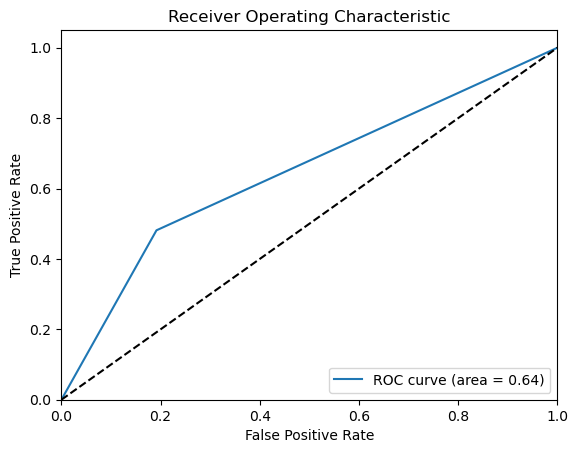

PR AUC: 0.367064600602792


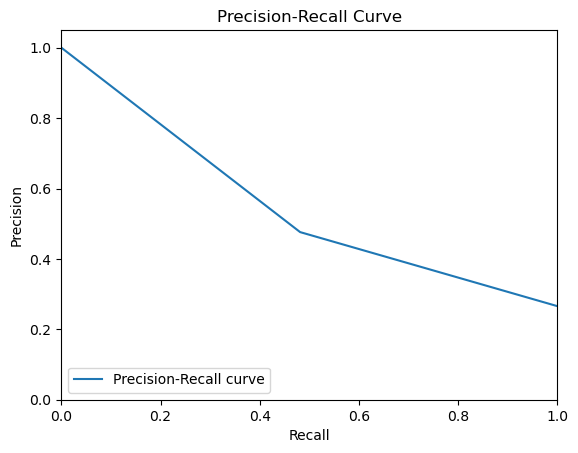

 31%|███       | 4/13 [00:11<00:26,  3.00s/it]


Confusion Matrix:
 [[765 268]
 [101 273]]


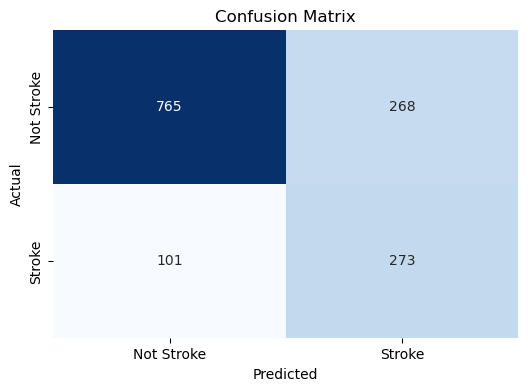


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.74      0.81      1033
      Stroke       0.50      0.73      0.60       374

    accuracy                           0.74      1407
   macro avg       0.69      0.74      0.70      1407
weighted avg       0.78      0.74      0.75      1407

ROC-AUC: 0.819356942812327


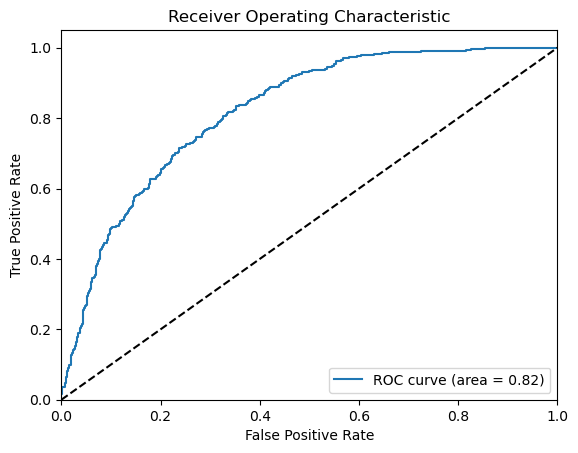

PR AUC: 0.5872321552521882


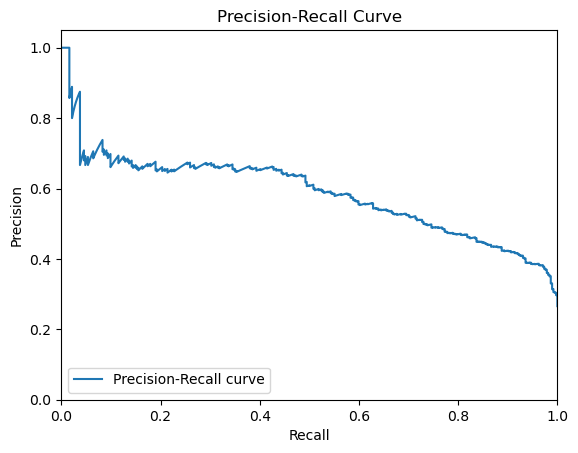

 38%|███▊      | 5/13 [00:11<00:16,  2.09s/it]


Confusion Matrix:
 [[915 118]
 [177 197]]


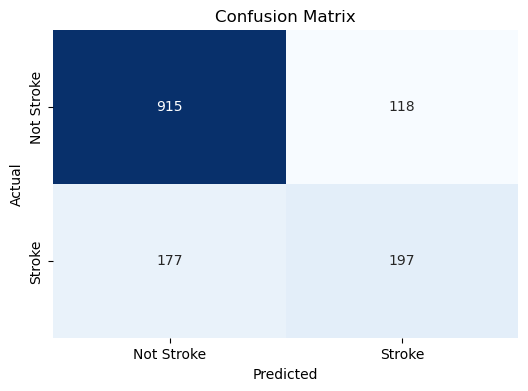


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.89      0.86      1033
      Stroke       0.63      0.53      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.78      1407

ROC-AUC: 0.8302708481086705


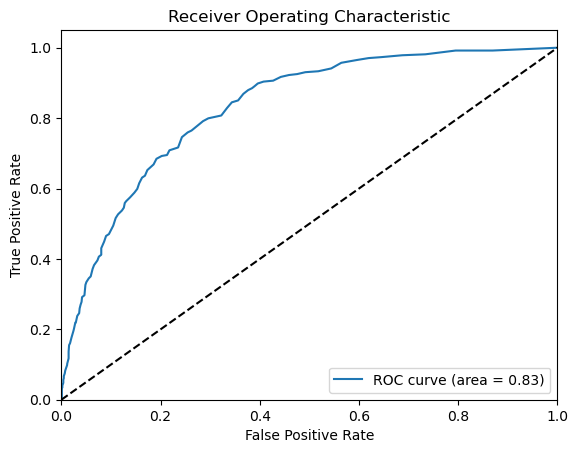

PR AUC: 0.6177477254521754


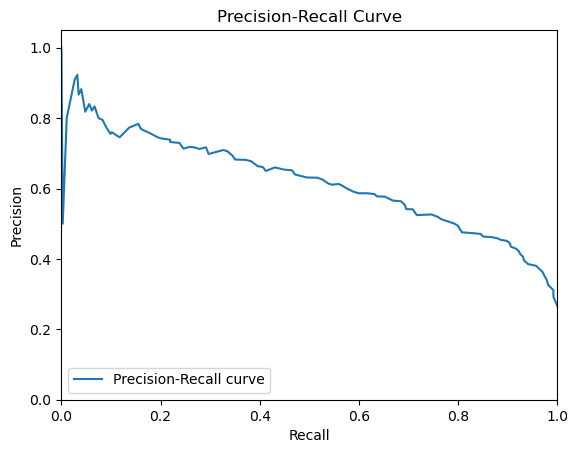

 46%|████▌     | 6/13 [00:13<00:13,  1.94s/it]


Confusion Matrix:
 [[910 123]
 [184 190]]


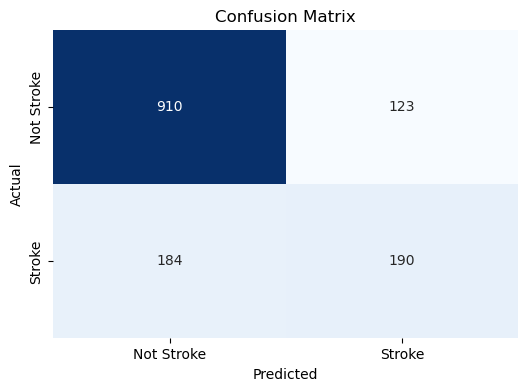


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.83      0.88      0.86      1033
      Stroke       0.61      0.51      0.55       374

    accuracy                           0.78      1407
   macro avg       0.72      0.69      0.70      1407
weighted avg       0.77      0.78      0.78      1407

ROC-AUC: 0.820842673072045


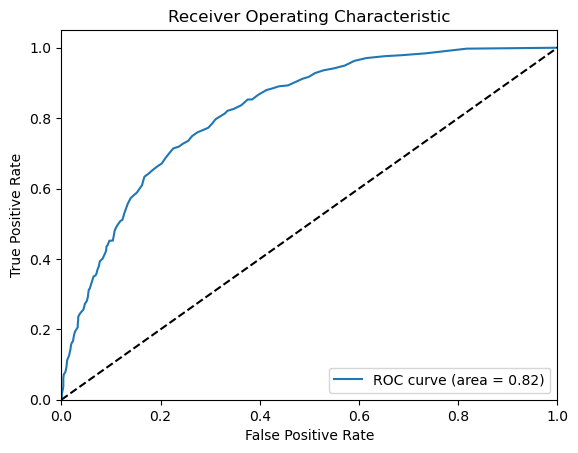

PR AUC: 0.5977943681225633


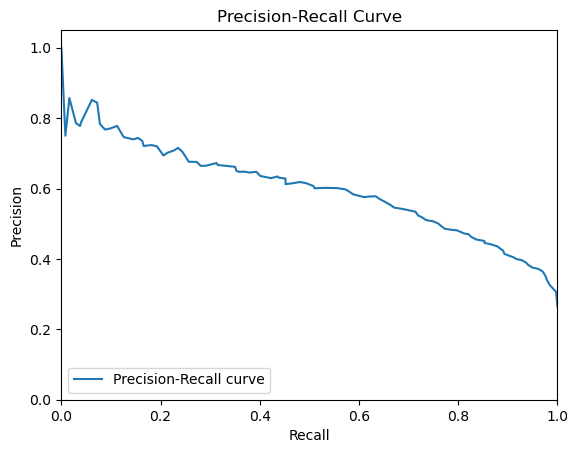

 54%|█████▍    | 7/13 [00:14<00:10,  1.78s/it]


Confusion Matrix:
 [[898 135]
 [153 221]]


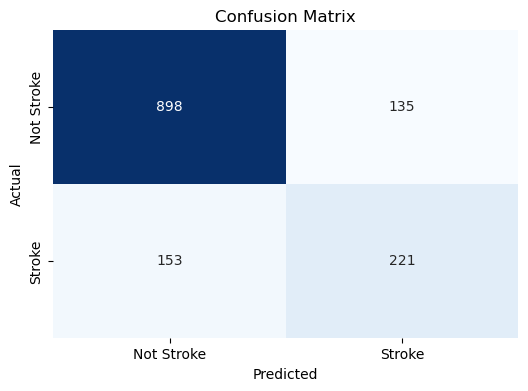


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.87      0.86      1033
      Stroke       0.62      0.59      0.61       374

    accuracy                           0.80      1407
   macro avg       0.74      0.73      0.73      1407
weighted avg       0.79      0.80      0.79      1407

ROC-AUC: 0.8396369020194542


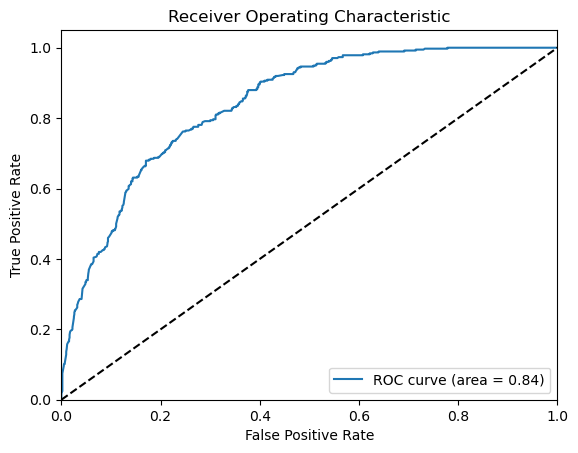

PR AUC: 0.6435626313372886


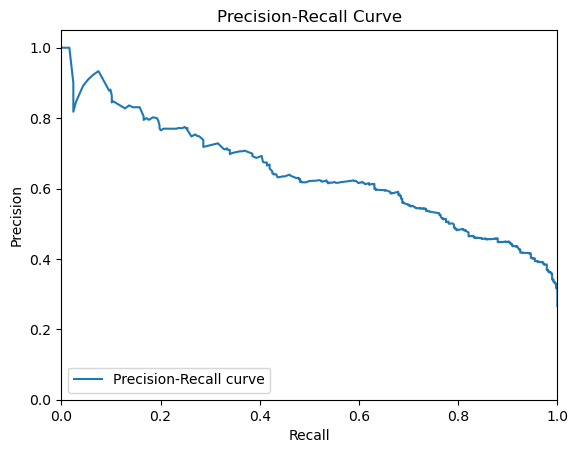

 62%|██████▏   | 8/13 [00:15<00:07,  1.54s/it]


Confusion Matrix:
 [[916 117]
 [163 211]]


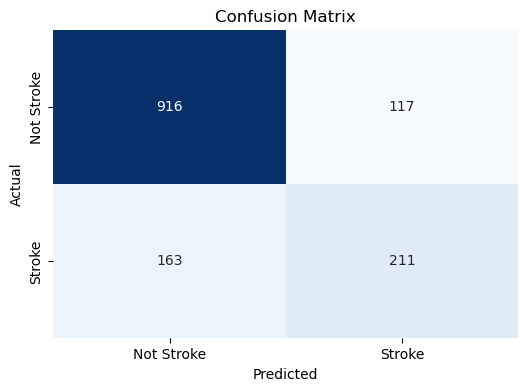


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.89      0.87      1033
      Stroke       0.64      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.73      1407
weighted avg       0.79      0.80      0.80      1407

ROC-AUC: 0.8465763494520399


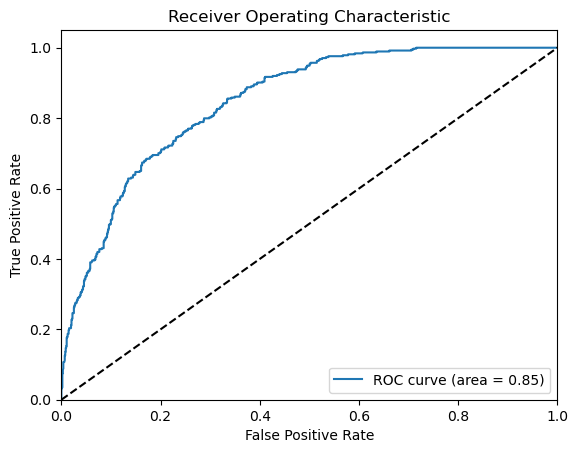

PR AUC: 0.6608396479099431


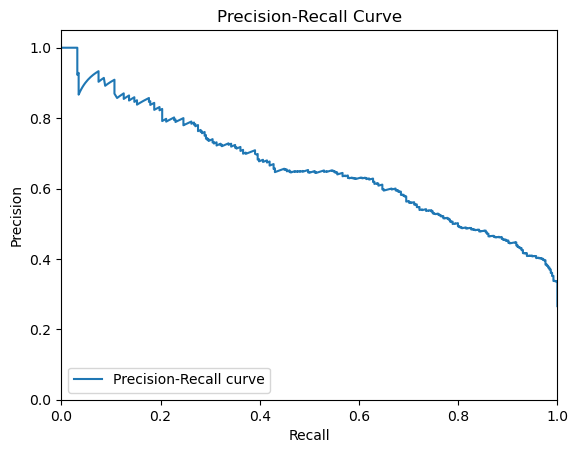

 69%|██████▉   | 9/13 [00:17<00:06,  1.52s/it]


Confusion Matrix:
 [[908 125]
 [162 212]]


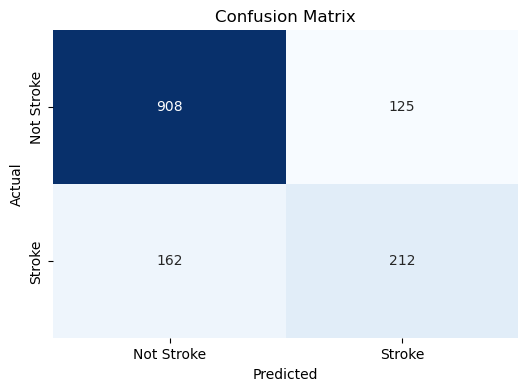


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.88      0.86      1033
      Stroke       0.63      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407

ROC-AUC: 0.8377642089133461


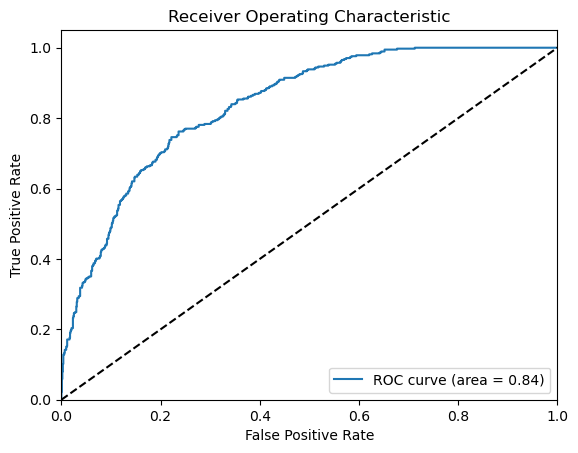

PR AUC: 0.6507023630666549


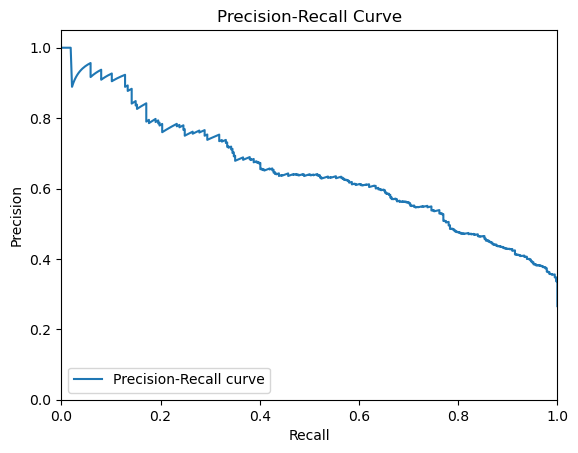

 77%|███████▋  | 10/13 [00:18<00:04,  1.52s/it]e:\anaconda\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:48:33] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[888 145]
 [177 197]]


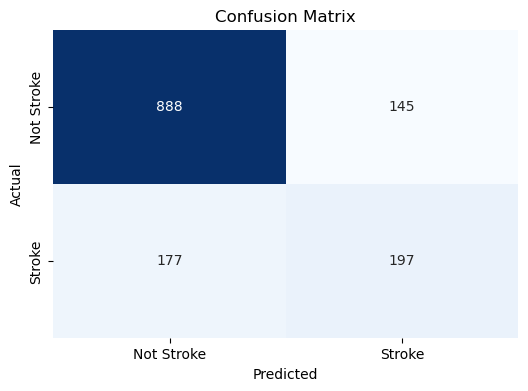


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.83      0.86      0.85      1033
      Stroke       0.58      0.53      0.55       374

    accuracy                           0.77      1407
   macro avg       0.70      0.69      0.70      1407
weighted avg       0.77      0.77      0.77      1407

ROC-AUC: 0.8285353391554633


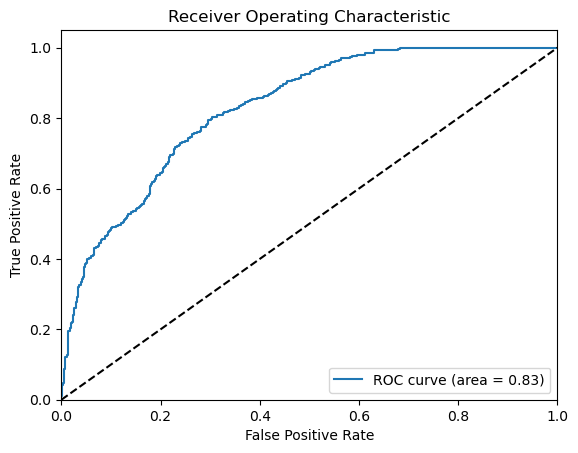

PR AUC: 0.6342582207889513


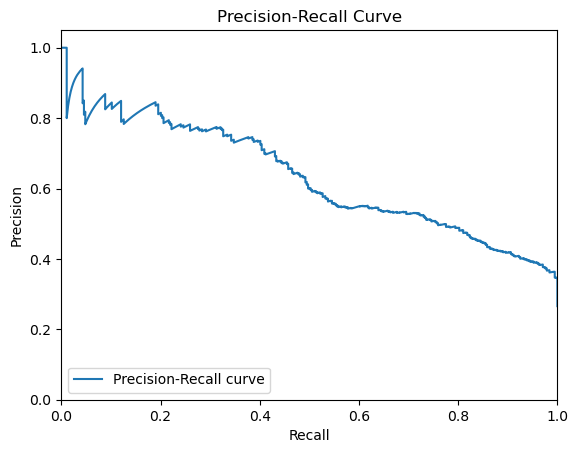

 85%|████████▍ | 11/13 [00:20<00:03,  1.62s/it]


Confusion Matrix:
 [[914 119]
 [171 203]]


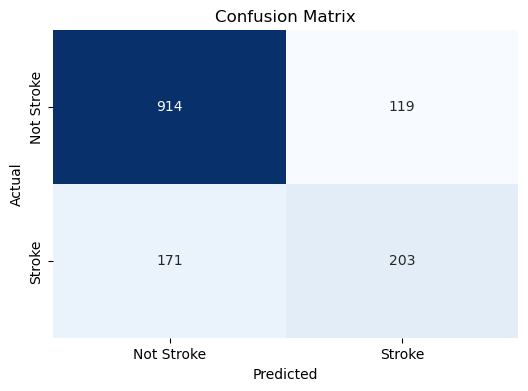


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.88      0.86      1033
      Stroke       0.63      0.54      0.58       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.79      0.79      1407

ROC-AUC: 0.8400264532460877


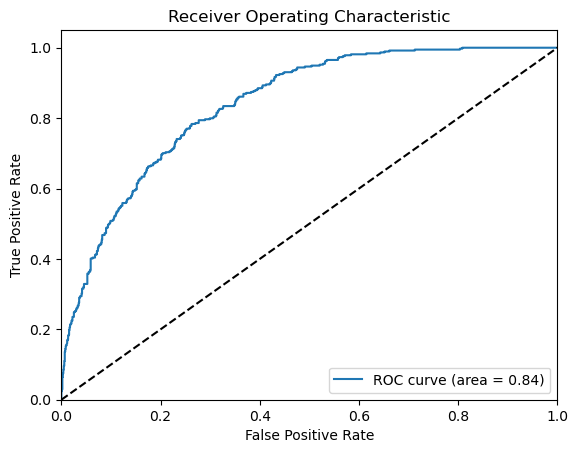

PR AUC: 0.650273168405412


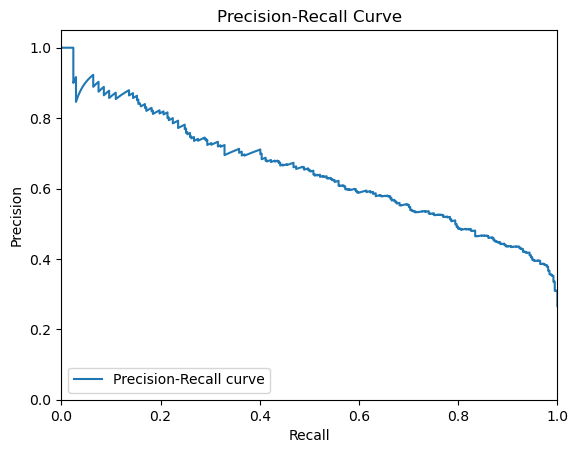

 92%|█████████▏| 12/13 [00:26<00:02,  2.87s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1495, number of negative: 4130
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000504 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 897
[LightGBM] [Info] Number of data points in the train set: 5625, number of used features: 20
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265778 -> initscore=-1.016151
[LightGBM] [Info] Start training from score -1.016151

Confusion Matrix:
 [[891 142]
 [164 210]]


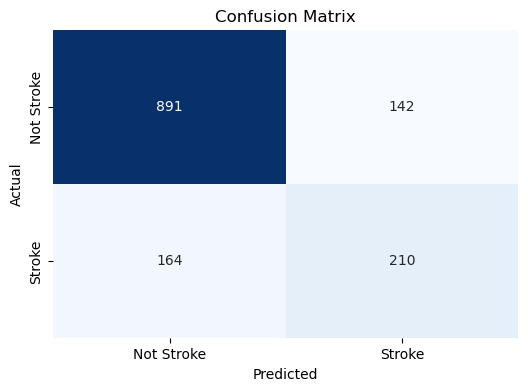


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.86      0.85      1033
      Stroke       0.60      0.56      0.58       374

    accuracy                           0.78      1407
   macro avg       0.72      0.71      0.72      1407
weighted avg       0.78      0.78      0.78      1407

ROC-AUC: 0.8363302462584964


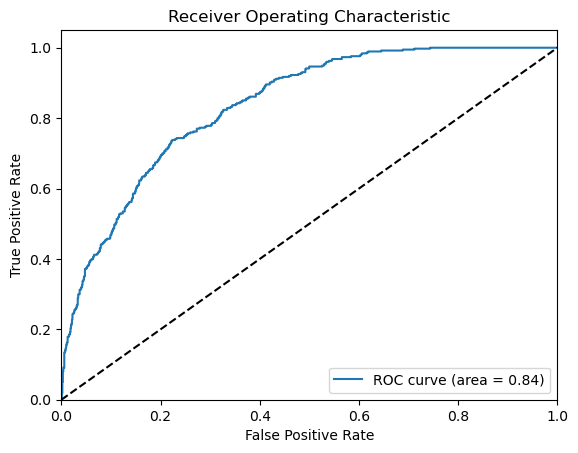

PR AUC: 0.6431557238292118


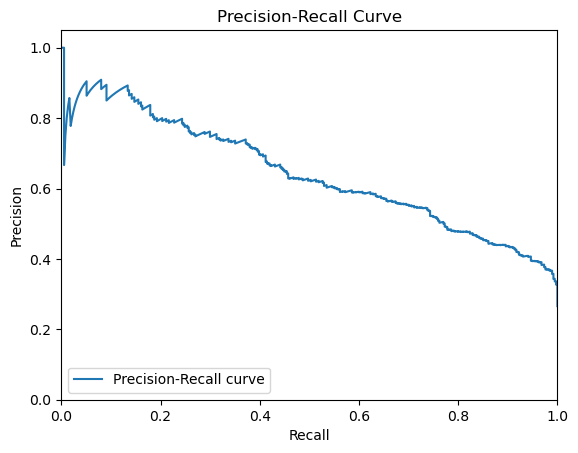

100%|██████████| 13/13 [00:27<00:00,  2.10s/it]


In [31]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred  = model.predict(X_test_scaled)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test_scaled)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

In [32]:
result = pd.DataFrame(results)

In [33]:
result

,Logistic Regression,KNN,SVC,Decision Tree,Naive Bayes,Random Forest,Extra Trees,AdaBoost,Gradient Boosting,Hist Gradient Boosting,XGBoost,CatBoost,LightGBM
Train Accuracy,0.809778,0.836800,0.836444,1.000000,0.769778,1.000000,1.000000,0.810133,0.835556,0.908978,0.962667,0.898844,0.907200
Test Accuracy,0.808102,0.762615,0.787491,0.721393,0.737740,0.790334,0.781805,0.795309,0.800995,0.796020,0.771144,0.793888,0.782516
Train Precision,0.659895,0.705631,0.745937,1.000000,0.548591,1.000000,1.000000,0.658972,0.728732,0.856418,0.932078,0.851824,0.849748
Test Precision,0.646893,0.552083,0.621359,0.476190,0.504621,0.625397,0.607029,0.620787,0.643293,0.629080,0.576023,0.630435,0.596591
Train Recall,0.586622,0.662207,0.583278,1.000000,0.755184,1.000000,1.000000,0.591973,0.607358,0.789967,0.927090,0.749833,0.790635
Test Recall,0.612299,0.566845,0.513369,0.481283,0.729947,0.526738,0.508021,0.590909,0.564171,0.566845,0.526738,0.542781,0.561497
Train F1 Score,0.621105,0.683230,0.654655,1.000000,0.635519,1.000000,1.000000,0.623679,0.662532,0.821851,0.929577,0.797581,0.819127
Test F1 Score,0.629121,0.559367,0.562225,0.478723,0.596721,0.571843,0.553130,0.605479,0.601140,0.596343,0.550279,0.583333,0.578512
Train Balanced Accuracy,0.738589,0.781104,0.755682,1.000000,0.765122,1.000000,1.000000,0.740539,0.762759,0.871012,0.951318,0.851309,0.870015
Test Balanced Accuracy,0.745646,0.700170,0.700053,0.644804,0.735254,0.706254,0.694475,0.730111,0.725454,0.722919,0.693185,0.713791,0.712017


In [34]:
results

{'Logistic Regression': {'Train Accuracy': 0.8097777777777778,
  'Test Accuracy': 0.8081023454157783,
  'Train Precision': 0.6598946576373212,
  'Test Precision': 0.6468926553672316,
  'Train Recall': 0.5866220735785953,
  'Test Recall': 0.6122994652406417,
  'Train F1 Score': 0.6211048158640227,
  'Test F1 Score': 0.6291208791208791,
  'Train Balanced Accuracy': 0.7385894871524938,
  'Test Balanced Accuracy': 0.7456463444305823,
  'ROC-AUC': 0.8422252822628655,
  'PR AUC': 0.6327276852871179},
 'KNN': {'Train Accuracy': 0.8368,
  'Test Accuracy': 0.7626154939587776,
  'Train Precision': 0.7056307911617962,
  'Test Precision': 0.5520833333333334,
  'Train Recall': 0.6622073578595318,
  'Test Recall': 0.5668449197860963,
  'Train F1 Score': 0.6832298136645962,
  'Test F1 Score': 0.5593667546174143,
  'Train Balanced Accuracy': 0.7811036789297658,
  'Test Balanced Accuracy': 0.7001697977439678,
  'ROC-AUC': 0.7841756785438808,
  'PR AUC': 0.5057463818175569},
 'SVC': {'Train Accuracy': 0

In [37]:
import numpy as np
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define focused parameter grids for your top 3 models
grids = {
    "Gradient Boosting (Tuned)": (
        GradientBoostingClassifier(random_state=42),
        {
            "n_estimators": [100, 200, 300],
            "learning_rate": [0.02, 0.05, 0.1],
            "max_depth": [2, 3, 4],
            "subsample": [0.8, 1.0],
            "min_samples_leaf": [5, 10, 20]
        }
    ),
    "Logistic Regression (Tuned)": (
        LogisticRegression(max_iter=1000, random_state=42),
        {
            "C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
            "penalty": ["l1", "l2"],
            "solver": ["liblinear"],
            "class_weight": [None, "balanced"]
        }
    ),
    "Hist Gradient Boosting (Tuned)": (
        HistGradientBoostingClassifier(random_state=42),
        {
            "max_iter": [100, 200, 300],
            "learning_rate": [0.02, 0.05, 0.1],
            "max_depth": [3, 4, 5],
            "l2_regularization": [1.0, 3.0, 5.0],
            "min_samples_leaf": [10, 20, 30],
            "class_weight": [None, "balanced"]
        }
    )
}

tuned_results = {}
best_estimators = {}

for name, (estimator, param_grid) in grids.items():
    grid = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )
    grid.fit(X_train_scaled, y_train)
    
    best_model = grid.best_estimator_
    best_estimators[name] = best_model
    
    # Predictions & Probabilities
    y_train_pred = best_model.predict(X_train_scaled)
    y_test_pred = best_model.predict(X_test_scaled)
    y_test_prob = best_model.predict_proba(X_test_scaled)[:, 1]
    
    tuned_results[name] = {
        "Best Params": grid.best_params_,
        "Best CV ROC-AUC": float(grid.best_score_),
        "Train Accuracy": float(accuracy_score(y_train, y_train_pred)),
        "Test Accuracy": float(accuracy_score(y_test, y_test_pred)),
        "Train Precision": float(precision_score(y_train, y_train_pred)),
        "Test Precision": float(precision_score(y_test, y_test_pred)),
        "Train Recall": float(recall_score(y_train, y_train_pred)),
        "Test Recall": float(recall_score(y_test, y_test_pred)),
        "Train F1 Score": float(f1_score(y_train, y_train_pred)),
        "Test F1 Score": float(f1_score(y_test, y_test_pred)),
        "Train Balanced Accuracy": float(balanced_accuracy_score(y_train, y_train_pred)),
        "Test Balanced Accuracy": float(balanced_accuracy_score(y_test, y_test_pred)),
        "ROC-AUC": float(roc_auc_score(y_test, y_test_prob)),
        "PR AUC": float(average_precision_score(y_test, y_test_prob))
    }

tuned_results

e:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
e:\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


{'Gradient Boosting (Tuned)': {'Best Params': {'learning_rate': 0.05,
   'max_depth': 4,
   'min_samples_leaf': 20,
   'n_estimators': 100,
   'subsample': 0.8},
  'Best CV ROC-AUC': 0.8643456396219845,
  'Train Accuracy': 0.8364444444444444,
  'Test Accuracy': 0.7967306325515281,
  'Train Precision': 0.7316680096696213,
  'Test Precision': 0.6392405063291139,
  'Train Recall': 0.6073578595317726,
  'Test Recall': 0.5401069518716578,
  'Train F1 Score': 0.6637426900584795,
  'Test F1 Score': 0.5855072463768116,
  'Train Balanced Accuracy': 0.7633641597900993,
  'Test Balanced Accuracy': 0.7148743859067872,
  'ROC-AUC': 0.8468507177578414,
  'PR AUC': 0.6601113584477781},
 'Logistic Regression (Tuned)': {'Best Params': {'C': 5,
   'class_weight': 'balanced',
   'penalty': 'l1',
   'solver': 'liblinear'},
  'Best CV ROC-AUC': 0.8590159288022221,
  'Train Accuracy': 0.7632,
  'Test Accuracy': 0.7334754797441365,
  'Train Precision': 0.5356673960612691,
  'Test Precision': 0.49916247906197

In [38]:
pd.DataFrame(tuned_results)

,Gradient Boosting (Tuned),Logistic Regression (Tuned),Hist Gradient Boosting (Tuned)
Best Params,"{'learning_rate': 0.05, 'max_depth': 4, 'min_s...","{'C': 5, 'class_weight': 'balanced', 'penalty'...","{'class_weight': None, 'l2_regularization': 3...."
Best CV ROC-AUC,0.864346,0.859016,0.864028
Train Accuracy,0.836444,0.7632,0.841067
Test Accuracy,0.796731,0.733475,0.803838
Train Precision,0.731668,0.535667,0.742926
Test Precision,0.639241,0.499162,0.654088
Train Recall,0.607358,0.818729,0.614716
Test Recall,0.540107,0.796791,0.55615
Train F1 Score,0.663743,0.647619,0.672767
Test F1 Score,0.585507,0.6138,0.601156


In [41]:
import joblib
import os

save_path = r"F:\NTI Machine\NTI projects\Final Project\telco_churn_pipeline.pkl"

artifacts = {
    "model": best_estimators["Hist Gradient Boosting (Tuned)"],
    "scaler": scaler,
    "encoders": encoders,
    "threshold": float(best_thresh) if "best_thresh" in globals() else 0.35,
    "feature_columns": X_train_scaled.columns.tolist()
}

joblib.dump(artifacts, save_path)
print("File exists:", os.path.exists(save_path))

File exists: True
